# Grouping Pulse Events # 

This notebook works to: 



In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree


import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
import string

ERROR 1: PROJ: proj_create_from_database: Open of /global/home/users/toireasamarie/.conda/envs/regrid_env2/share/proj failed


In [2]:
file ='/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_with_incdec.parquet'
df = pd.read_parquet(file, engine='pyarrow')

In [3]:
df.head(7)

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,pre_slope,sm_class
0,36.05,-91.15,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
1,36.05,-91.15,NaN,2024-02-29 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
2,36.05,-91.15,NaN,2024-03-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
3,36.05,-91.15,NaN,2024-03-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
4,36.05,-91.15,NaN,2024-03-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
5,36.05,-91.15,NaN,2024-03-01 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
6,36.05,-91.15,NaN,2024-03-01 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None


In [4]:
df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name', 'pre_slope', 'sm_class'],
      dtype='object')

# subset pulse starts

In [5]:
pulse_df = df[df["pulse_start"] == True].copy()

pulse_df["datetime"] = pd.to_datetime(pulse_df["datetime"])
pulse_df = pulse_df.sort_values("datetime").reset_index(drop=True)

In [6]:
#defining thresholds
spatial_degree = 0.2 #within ~20km 
time_hours = 24 #pulses within 1 day

In [7]:
pulse_df = pulse_df.copy()
pulse_df["datetime"] = pd.to_datetime(pulse_df["datetime"])

#time in hours since first pulse
pulse_df["time_num"] =(pulse_df["datetime"] -pulse_df["datetime"].min()).dt.total_seconds() /3600

#ckd tree only in spatial coordinates
spatial_coords = pulse_df[["grid_lat", "grid_lon"]].to_numpy()
tree =cKDTree(spatial_coords)

#find candidate spatial neighbors within 0.2 degrees
candidate_pairs = tree.query_pairs(r=spatial_degree)

#keep only pairs also within 24 hours
valid_pairs = []
times = pulse_df["time_num"].to_numpy()

for i, j in candidate_pairs:
    if abs(times[i] - times[j]) <= time_hours:
        valid_pairs.append((i, j))

#union find to group connected comps 
parent = np.arange(len(pulse_df))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]  
        x =parent[x]
    return x

def union(x, y):
    parent[find(x)] =find(y)

for i, j in valid_pairs:
    union(i, j)

pulse_df["group_id"] = [find(i) for i in range(len(pulse_df))]

In [8]:
pulse_df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name', 'pre_slope', 'sm_class',
       'time_num', 'group_id'],
      dtype='object')

In [9]:
output_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_grouped_2hour_pulses.parquet'
pulse_df.to_parquet(output_file, engine='pyarrow')

# EDA

- finding events with precip before the pulse
- and no2 observations present for every day within the window

In [10]:
pre_pulse_days= 5  #how many days before the pulse to look for precip
post_pulse_days = 5  #how many days after the pulse must have NO2 obs
min_precip_mm = 2.0  #total precip (mm, summed over all cells x hours) needed in pre-window
min_event_cells = 3 #how big the event is 
required_no2_days = post_pulse_days # Every one of the post-window days must have a NO2 reading
min_cells_per_day = 1 # At least this many cells with non-NaN NO2 on each post day
no2_pre_days = 5 #days before pulse that must have NO2 obs
no2_post_days = 5 #days after pulse that must have NO2 obs

df_ = df.copy()
df_["datetime"] =pd.to_datetime(df_["datetime"])
df_["date"] =df_["datetime"].dt.normalize()

pulse_df_ =pulse_df.copy()
pulse_df_["datetime"] = pd.to_datetime(pulse_df_["datetime"])

In [11]:
#event metadata 
event_meta = (pulse_df_.groupby("group_id").agg(
    n_cells= ("grid_lat", "count"),
    t0 = ("datetime", "min"),
    centroid_lat =("grid_lat", "mean"),
    centroid_lon = ("grid_lon", "mean")).reset_index())

#keep only events large enough
event_meta = event_meta[event_meta["n_cells"] >= min_event_cells].copy()
event_meta["t0"] = pd.to_datetime(event_meta["t0"])
event_meta["t0_date"] = event_meta["t0"].dt.normalize()

print(f"Candidate events (≥{min_event_cells} cells): {len(event_meta)}")

Candidate events (≥3 cells): 149


In [12]:
#score each event
records =[]

for _, row in event_meta.iterrows():
    eid = row["group_id"]
    t0= row["t0"]
    t0d = row["t0_date"]

    event_cells = (pulse_df_[pulse_df_["group_id"] == eid][["grid_lat", "grid_lon"]].drop_duplicates())

    sub = df_.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner")

    #precipitation in previous days 
    pre = sub[(sub["datetime"] >= t0 - pd.Timedelta(days=pre_pulse_days)) & (sub["datetime"] <  t0)].copy()
    total_precip = pd.to_numeric(pre["h_precip_mm"], errors="coerce").sum()
    pre["date"] = pre["datetime"].dt.normalize()
    daily_precip = pre.groupby("date")["h_precip_mm"].apply(
        lambda x: pd.to_numeric(x, errors="coerce").sum()
    )
    n_precip_days = (daily_precip > 0.1).sum()

    #want no2 for every day
    no2_window = sub[(sub["date"] >=t0d - pd.Timedelta(days=no2_pre_days)) &
    (sub["date"] <=t0d + pd.Timedelta(days=no2_post_days)) &
    (sub["date"] !=t0d)   #want toexclude the pulse day itself
    ].copy()

    daily_no2_cells = (no2_window.groupby("date")["no2_mean"].apply(lambda x: x.notna().sum()))

    expected_dates = pd.date_range(t0d - pd.Timedelta(days=no2_pre_days), 
                                   t0d + pd.Timedelta(days=no2_post_days), freq="D").normalize()
    expected_dates =expected_dates[expected_dates !=t0d]

    covered_dates= set(daily_no2_cells[daily_no2_cells >= min_cells_per_day].index.normalize())
    all_days_covered =set(expected_dates).issubset(covered_dates)

    days_with_no2 =(daily_no2_cells >=min_cells_per_day).sum()

    records.append({
        "group_id": eid,
        "n_cells": row["n_cells"],
        "t0": t0,
        "centroid_lat": row["centroid_lat"],
        "centroid_lon": row["centroid_lon"],
        "total_precip_mm": round(total_precip, 2),
        "n_precip_days": int(n_precip_days),
        "days_with_no2": int(days_with_no2),
        "all_days_covered": all_days_covered})

scored = pd.DataFrame(records)

In [14]:
#applyingtwo main filters
exemplars = scored[(scored["total_precip_mm"] >= min_precip_mm) & (scored["all_days_covered"] ==True)].copy()

exemplars = exemplars.sort_values(["total_precip_mm", "n_cells"], ascending=False).reset_index(drop=True)

print(f"\nNumber of exemplar events found: {len(exemplars)}")
print(f" (precip ≥ {min_precip_mm} mm in {pre_pulse_days} pre-days  AND  NO2 on all {no2_pre_days} pre + {no2_post_days} post days)\n")

print(exemplars[[ "group_id", "t0", "n_cells", "centroid_lat", "centroid_lon", 
                 "total_precip_mm", "n_precip_days", "days_with_no2"]].to_string(index=False))


Number of exemplar events found: 14
 (precip ≥ 2.0 mm in 5 pre-days  AND  NO2 on all 5 pre + 5 post days)

 group_id                  t0  n_cells  centroid_lat  centroid_lon  total_precip_mm  n_precip_days  days_with_no2
     1907 2024-07-13 15:00:00       26     40.288462    -98.926923           793.54              5             10
     1919 2024-07-12 16:00:00       29     40.243103    -97.553448           261.25              6             10
     1809 2024-07-09 15:00:00       15     40.776667    -95.963333           219.59              4             10
     1807 2024-07-09 15:00:00        5     40.250000    -96.730000            97.45              4             10
     1886 2024-07-13 15:00:00        4     39.700000    -98.800000            84.59              4             10
     1897 2024-07-13 15:00:00        7     40.050000    -98.192857            64.31              4             10
     1728 2024-07-08 15:00:00       15     40.743333    -99.910000            50.74           

/tmp/ipykernel_1602434/1386936137.py:214: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.02, 1, 0.99])


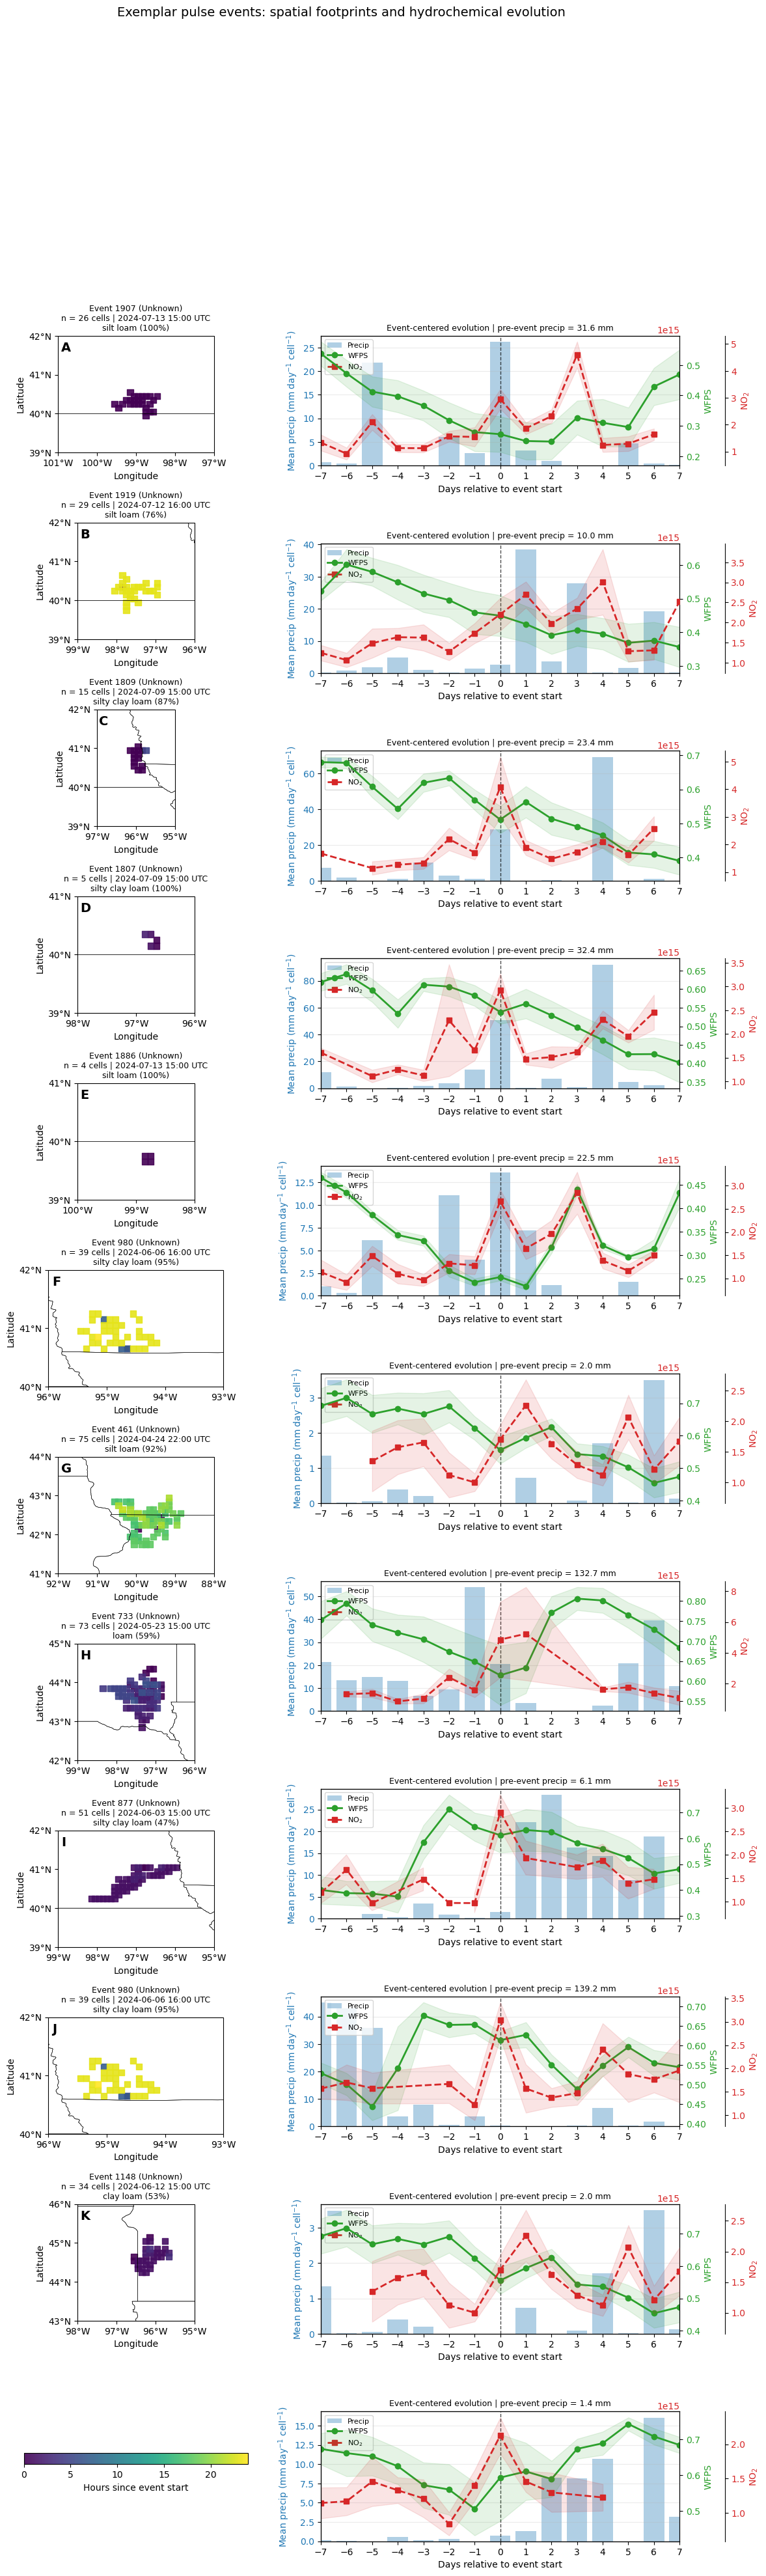

In [15]:
events_to_plot = [1907, 1919, 1809, 1807, 1886, 980,
                  461, 733, 877, 980, 1148]

window_days = 7

# auto-generate enough panel labels
panel_labels = [f"{letter}{num if num > 0 else ''}"
                for num in range(10)
for letter in string.ascii_uppercase]

#data preparation
df = df.copy()
pulse_df = pulse_df.copy()

df["datetime"] = pd.to_datetime(df["datetime"])
pulse_df["datetime"] =pd.to_datetime(pulse_df["datetime"])

events_to_plot = [
    eid for eid in events_to_plot
    if eid in pulse_df["group_id"].unique()]

n_events = len(events_to_plot)

#figure setup
fig = plt.figure(figsize=(13, 4 * n_events))
outer = gridspec.GridSpec(n_events, 1, hspace=0.6)
map_axes = []
last_sc = None

#color range for hours since start
all_event_pulses = pulse_df[pulse_df["group_id"].isin(events_to_plot)].copy()
all_event_pulses["hours_since_start"] = (all_event_pulses["datetime"] - all_event_pulses.groupby("group_id")["datetime"]
                                         .transform("min")).dt.total_seconds() / 3600

vmin_time = 0
vmax_time = all_event_pulses["hours_since_start"].max()

#loop through vents
for row, eid in enumerate(events_to_plot):

    inner = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer[row], width_ratios=[1.0, 1.6], wspace=0.25)

    #event data
    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells =event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()

    if event_pulses.empty:
        continue

    t0 =event_pulses["datetime"].min()

    event_pulses["hours_since_start"] = ((event_pulses["datetime"] -t0).dt.total_seconds() /3600)

    #soil texture 
    if "dominant_texture" in event_pulses.columns:
        event_soils = (event_pulses[["grid_lat", "grid_lon", "dominant_texture"]] 
                       .drop_duplicates(subset=["grid_lat", "grid_lon"])
                       .dropna(subset=["dominant_texture"]))

        if len(event_soils) >0:
            soil_counts = event_soils["dominant_texture"].value_counts()
            dominant_soil =soil_counts.index[0]
            dominant_soil_frac = soil_counts.iloc[0] / soil_counts.sum()
            soil_str =f"{dominant_soil} ({dominant_soil_frac:.0%})"
        else:
            soil_str = "Soil texture unknown"
    else:
        soil_str = ""

    #sm class
    try:
        sm_label = event_sm_frac.loc[eid, "dominant_class"]
    except Exception:
        sm_label ="Unknown"

    #window time series 
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()

    sub =sub[(sub["datetime"] >= t0 - pd.Timedelta(days=window_days)) & 
    (sub["datetime"] <= t0 + pd.Timedelta(days=window_days))].copy()

    sub["lag_day"] = np.floor((sub["datetime"] - t0).dt.total_seconds() /86400.0).astype(int)

    #daily aggregate per cell 
    agg_cell = {"precip": ("h_precip_mm", "sum"),
                "no2": ("no2_mean", "mean")}

    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c", "mean")

    cell_daily = (sub.groupby(["grid_lat", "grid_lon", "lag_day"]).agg(**agg_cell).reset_index())

    #aggregate across event cells 
    agg_event = {"precip_mean": ("precip", "mean"), "precip_std": ("precip", "std"),
                 "no2_mean": ("no2", "mean"), "no2_std": ("no2", "std")}
    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps", "mean")
        agg_event["wfps_std"]= ("wfps", "std")
    event_daily = (cell_daily.groupby("lag_day").agg(**agg_event).reset_index())

    #add missing lag days
    full_lags = pd.DataFrame({"lag_day": np.arange(-window_days, window_days + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily["precip_mean"] = event_daily["precip_mean"].fillna(0)
    event_daily["precip_std"] = event_daily["precip_std"].fillna(0)

    #left panel is the map
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)
    lon_min = event_cells["grid_lon"].min() - 0.5
    lon_max = event_cells["grid_lon"].max() + 0.5
    lat_min = event_cells["grid_lat"].min() - 0.5
    lat_max = event_cells["grid_lat"].max() + 0.5

    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax_map.coastlines(linewidth=0.3)

    sc = ax_map.scatter(event_pulses["grid_lon"], event_pulses["grid_lat"], c=event_pulses["hours_since_start"],
                        cmap="viridis", vmin=vmin_time, vmax=vmax_time, s=45, marker="s", alpha=0.9, 
                        transform=ccrs.PlateCarree())

    last_sc = sc
    xticks = np.arange(np.floor(lon_min), np.ceil(lon_max) + 1, 1)
    yticks = np.arange(np.floor(lat_min), np.ceil(lat_max) + 1, 1)
    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.set_xlabel("Longitude")
    ax_map.set_ylabel("Latitude")
    ax_map.text( 0.02, 0.95, panel_labels[row], transform=ax_map.transAxes, fontsize=14, fontweight="bold",
                va="top", ha="left")

    title = ( f"Event {eid} ({sm_label})\n"
             f"n = {len(event_cells)} cells | {t0:%Y-%m-%d %H:%M} UTC")

    if soil_str:
        title += f"\n{soil_str}"

    ax_map.set_title(title, fontsize=9)

    #right panel is the time series
    ax_ts = fig.add_subplot(inner[1])

    ax_ts.bar( event_daily["lag_day"], event_daily["precip_mean"], color="tab:blue", alpha=0.35, width=0.8, 
              label="Precip")
    ax_ts.set_ylabel("Mean precip (mm day$^{-1}$ cell$^{-1}$)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--", linewidth=1, alpha=0.7)
    ax_ts.grid(True, axis="y", alpha=0.25)

    #wfps axis 
    has_wfps = "wfps_mean" in event_daily.columns

    if has_wfps:
        ax_wfps = ax_ts.twinx()

        valid_wfps = event_daily["wfps_mean"].notna()

        ax_wfps.plot(event_daily.loc[valid_wfps, "lag_day"], event_daily.loc[valid_wfps, "wfps_mean"],
                     color="tab:green", marker="o", linewidth=2, label="WFPS")

        ax_wfps.fill_between(event_daily.loc[valid_wfps, "lag_day"],
                             (event_daily["wfps_mean"] - event_daily["wfps_std"]).loc[valid_wfps],
                             (event_daily["wfps_mean"] + event_daily["wfps_std"]).loc[valid_wfps],
                             color="tab:green",alpha=0.12)

        ax_wfps.set_ylabel("WFPS", color="tab:green")
        ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    #no2 axis
    ax_no2 = ax_ts.twinx()

    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 50))

    valid_no2 = event_daily["no2_mean"].notna()

    ax_no2.plot(event_daily.loc[valid_no2, "lag_day"], event_daily.loc[valid_no2, "no2_mean"],
                color="tab:red", linestyle="--",marker="s",linewidth=2, label="NO$_2$")

    ax_no2.fill_between(event_daily.loc[valid_no2, "lag_day"],
                        (event_daily["no2_mean"] - event_daily["no2_std"]).loc[valid_no2],
                        (event_daily["no2_mean"] + event_daily["no2_std"]).loc[valid_no2],
                        color="tab:red", alpha=0.12)

    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")
    ax_ts.set_xlim(-window_days, window_days)
    ax_ts.set_xticks(np.arange(-window_days, window_days + 1, 1))
    ax_ts.set_xlabel("Days relative to event start")

    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()

    ax_ts.set_title(f"Event-centered evolution | pre-event precip = {pre_precip:.1f} mm", fontsize=9)

    #legend 
    handles = [Patch(facecolor="tab:blue", alpha=0.35, label="Precip"), Line2D([0], [0], color="tab:red", linestyle="--",
                                                                               marker="s", linewidth=2, label="NO$_2$")]

    if has_wfps:
        handles.insert(1, Line2D([0], [0], color="tab:green", marker="o", linewidth=2, label="WFPS"))

    ax_ts.legend(handles=handles, fontsize=8, loc="upper left", frameon=True)

#colorbar
if last_sc is not None:
    cbar = fig.colorbar(last_sc, ax=map_axes, orientation="horizontal", fraction=0.04, pad=0.06)
    cbar.set_label("Hours since event start")

fig.suptitle("Exemplar pulse events: spatial footprints and hydrochemical evolution",fontsize=14, y=0.995)
plt.tight_layout(rect=[0, 0.02, 1, 0.99])
#plt.savefig("exemplar_events.png",dpi=150, bbox_inches="tight")
plt.show()

# Temporal and spatial plots 

In [10]:
event_summary = (pulse_df.groupby("group_id").agg(
    n_cells=("grid_lat", "count"),
    mean_no2=("no2_mean", "mean"),
    max_no2=("no2_mean", "max"),
    std_no2=("no2_mean", "std"),
    start_time=("datetime", "min"),
    start_hour_local=("local_hour", "min"),
    duration_hours=("datetime", lambda x: (x.max() - x.min()).total_seconds()/3600),
    mean_precip=("h_precip_mm", "mean"),
).reset_index())

In [11]:
event_summary

,group_id,n_cells,mean_no2,max_no2,std_no2,start_time,start_hour_local,duration_hours,mean_precip
0,0,1,2.173031e+15,2.173031e+15,NaN,2024-03-13 16:00:00,11.0,0.0,0.000
1,1,1,4.694567e+15,4.694567e+15,NaN,2024-03-16 15:00:00,10.0,0.0,0.000
2,3,6,2.656517e+15,2.904745e+15,1.279930e+14,2024-03-16 15:00:00,10.0,0.0,0.000
3,9,2,4.539784e+15,4.878880e+15,4.795547e+14,2024-03-16 15:00:00,10.0,0.0,0.000
4,10,1,3.730113e+15,3.730113e+15,NaN,2024-03-18 20:00:00,15.0,0.0,0.065
...,...,...,...,...,...,...,...,...,...
772,2004,1,3.003975e+15,3.003975e+15,NaN,2024-07-19 15:00:00,10.0,0.0,0.000
773,2005,1,2.530260e+15,2.530260e+15,NaN,2024-07-19 16:00:00,11.0,0.0,0.000
774,2006,1,2.812737e+15,2.812737e+15,NaN,2024-07-19 18:00:00,13.0,0.0,0.105
775,2007,1,2.959582e+15,2.959582e+15,NaN,2024-07-19 18:00:00,13.0,0.0,0.000


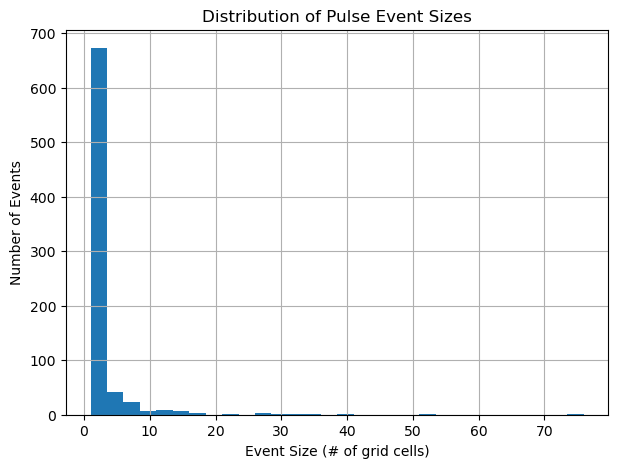

In [12]:
plt.figure(figsize=(7,5))

plt.hist(event_summary["n_cells"], bins=30)

plt.xlabel("Event Size (# of grid cells)")
plt.ylabel("Number of Events")
plt.title("Distribution of Pulse Event Sizes")

plt.grid(True)
plt.show()

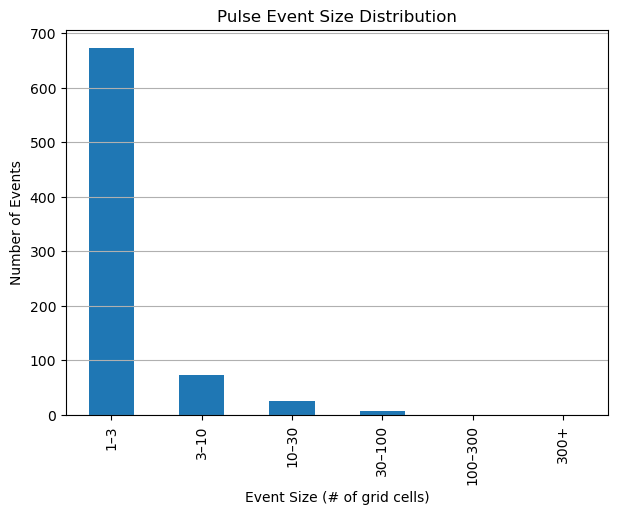

In [13]:
event_summary["size_bin"] = pd.cut(
    event_summary["n_cells"],
    bins=[0, 3, 10, 30, 100, 300, 1000],
    labels=["1–3", "3–10", "10–30", "30–100", "100–300", "300+"])

size_counts = (event_summary["size_bin"].value_counts().sort_index())
plt.figure(figsize=(7,5))

size_counts.plot(kind="bar")

plt.xlabel("Event Size (# of grid cells)")
plt.ylabel("Number of Events")
plt.title("Pulse Event Size Distribution")

plt.grid(axis="y")
plt.show()

In [14]:
event_summary.columns

Index(['group_id', 'n_cells', 'mean_no2', 'max_no2', 'std_no2', 'start_time',
       'start_hour_local', 'duration_hours', 'mean_precip', 'size_bin'],
      dtype='object')

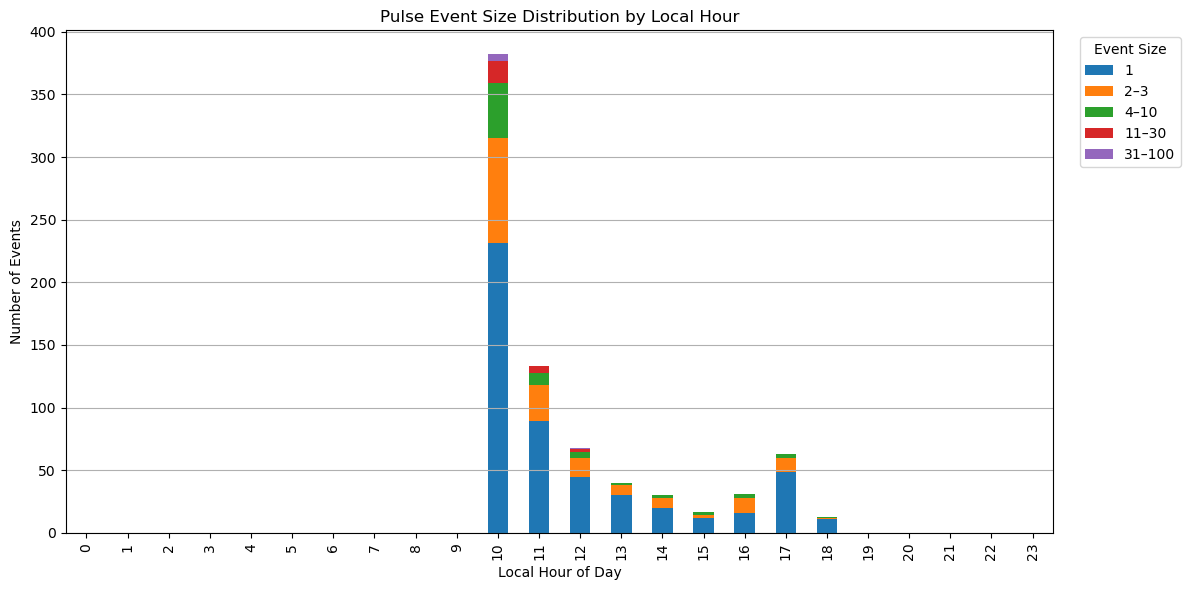

In [15]:
event_summary["size_bin"] = pd.cut(
    event_summary["n_cells"],
    bins=[0, 1, 3, 10, 30, 100, 300, np.inf],
    labels=["1", "2–3", "4–10", "11–30", "31–100", "101–300", "300+"],
    include_lowest=True)

counts = (event_summary.groupby(["start_hour_local", "size_bin"], observed=True).size()
          .unstack(fill_value=0))

counts = counts.reindex(range(24), fill_value=0)

counts.plot(kind="bar",stacked=True,figsize=(12, 6))

plt.xlabel("Local Hour of Day")
plt.ylabel("Number of Events")
plt.title("Pulse Event Size Distribution by Local Hour")

plt.legend(title="Event Size", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

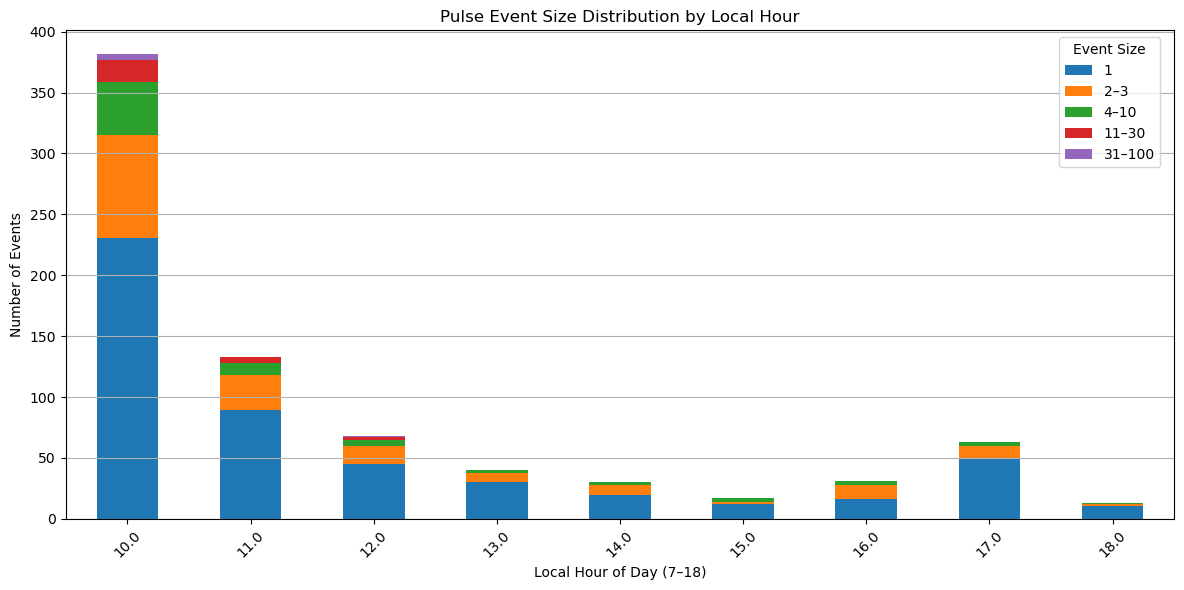

In [16]:
counts = (event_summary.groupby(["start_hour_local", "size_bin"], observed=True).size()
          .unstack(fill_value=0))

#only want 7-18 hours
counts = counts.loc[7:18]

counts.plot(kind="bar", stacked=True, figsize=(12, 6))

plt.xlabel("Local Hour of Day (7–18)")
plt.xticks(rotation=45)
plt.ylabel("Number of Events")
plt.title("Pulse Event Size Distribution by Local Hour")

plt.legend(title="Event Size", bbox_to_anchor=(0.89, 1), loc="upper left")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

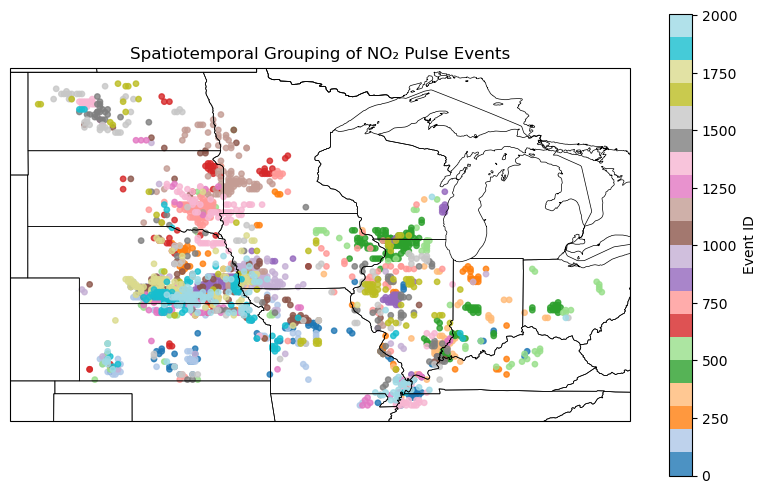

In [17]:
plot_df = pulse_df.copy()

fig = plt.figure(figsize=(10,6))
ax =plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.coastlines()

# scatter colored by group_id
sc = ax.scatter(plot_df["grid_lon"], plot_df["grid_lat"], c=plot_df["group_id"], cmap="tab20",
                s=15, alpha=0.8, transform=ccrs.PlateCarree())

plt.colorbar(sc, ax=ax, label="Event ID")
ax.set_title("Spatiotemporal Grouping of NO₂ Pulse Events")
plt.show()

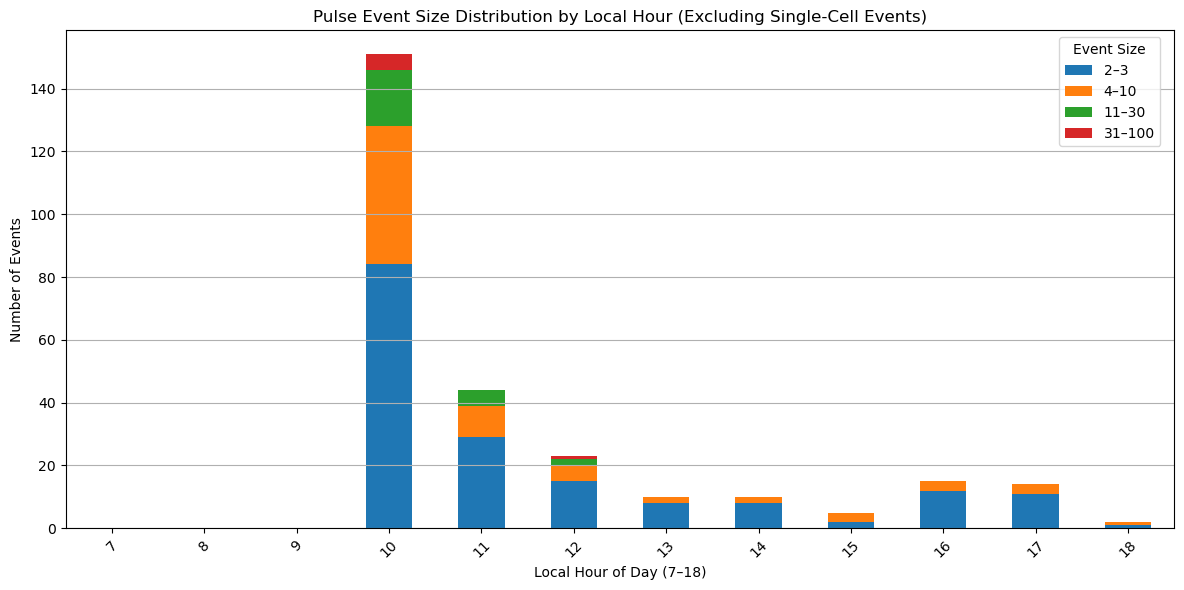

In [18]:
# remove single-cell events
event_summary_filtered = event_summary[event_summary["n_cells"] > 1]

counts = (event_summary_filtered[event_summary_filtered["start_hour_local"].between(7, 18)]
          .groupby(["start_hour_local", "size_bin"], observed=True).size()
          .unstack(fill_value=0))
counts = counts.reindex(range(7, 19), fill_value=0)

counts.plot(kind="bar", stacked=True, figsize=(12, 6))

plt.xlabel("Local Hour of Day (7–18)")
plt.ylabel("Number of Events")
plt.title("Pulse Event Size Distribution by Local Hour (Excluding Single-Cell Events)")
plt.xticks(rotation=45)

plt.legend(title="Event Size", bbox_to_anchor=(0.89, 1), loc="upper left")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

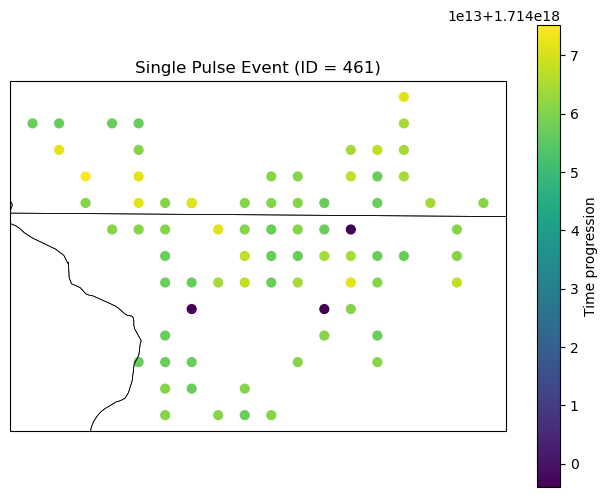

In [19]:
event_sizes = pulse_df["group_id"].value_counts()

big_group_id = event_sizes.index[0]  # largest event
event_df = pulse_df[pulse_df["group_id"] == big_group_id]

fig = plt.figure(figsize=(8,6))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.coastlines()

sc = ax.scatter(event_df["grid_lon"], event_df["grid_lat"], c=event_df["datetime"].astype("int64"),  #color by time
    cmap="viridis",s=40, transform=ccrs.PlateCarree())

plt.colorbar(sc, ax=ax, label="Time progression")
ax.set_title(f"Single Pulse Event (ID = {big_group_id})")
plt.show()

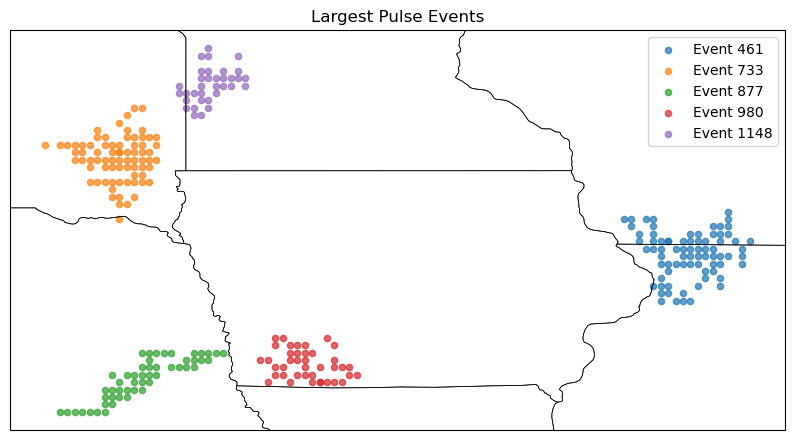

In [20]:
top_events = event_sizes.head(5).index

fig = plt.figure(figsize=(10,6))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.coastlines()

for eid in top_events:
    sub = pulse_df[pulse_df["group_id"] == eid]
    
    ax.scatter(sub["grid_lon"],sub["grid_lat"],label=f"Event {eid}", s=20,
               alpha=0.7,transform=ccrs.PlateCarree())

ax.legend()
ax.set_title("Largest Pulse Events")
plt.show()

In [21]:
# total individual pulse detections
n_pulses = len(pulse_df)

# total grouped events
n_events = pulse_df["group_id"].nunique()

print("Individual pulses:", n_pulses)
print("Grouped events:", n_events)

Individual pulses: 2009
Grouped events: 777


In [22]:
reduction_factor = n_pulses / n_events

print("Reduction factor:", reduction_factor)

Reduction factor: 2.5855855855855854


In [23]:
summary = {
    "Total individual pulses": n_pulses,
    "Total grouped events": n_events,
    "Mean event size": event_sizes.mean(),
    "Median event size": event_sizes.median(),
    "Max event size": event_sizes.max()
}

for k, v in summary.items():
    print(f"{k}: {v:.2f}")

Total individual pulses: 2009.00
Total grouped events: 777.00
Mean event size: 2.59
Median event size: 1.00
Max event size: 76.00


# are grouped events correlated with soil moisture changes?

In [25]:
pulse_df = pulse_df.dropna(subset=["sm_class"])

In [26]:
event_sm_counts = (pulse_df.groupby(["group_id", "sm_class"]).size().unstack(fill_value=0))
event_sm_frac = event_sm_counts.div(event_sm_counts.sum(axis=1), axis=0)

In [27]:
threshold = 0.7
numeric_cols = event_sm_counts.columns  #"Increasing" or "Decreasing"

event_sm_frac["dominant_class"] = event_sm_frac[numeric_cols].idxmax(axis=1)
event_sm_frac["dominant_frac"] =event_sm_frac[numeric_cols].max(axis=1)

event_sm_frac["coherent"] =event_sm_frac["dominant_frac"] >=threshold

In [28]:
n_events = len(event_sm_frac)
n_coherent = event_sm_frac["coherent"].sum()

print("Total events:", n_events)
print("Coherent events:", n_coherent)
print("Fraction coherent:", n_coherent / n_events)

Total events: 777
Coherent events: 759
Fraction coherent: 0.9768339768339769


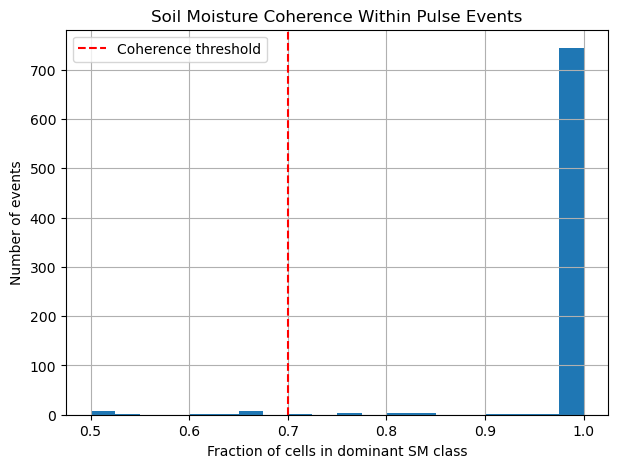

In [29]:
plt.figure(figsize=(7,5))

plt.hist(event_sm_frac["dominant_frac"], bins=20)

plt.xlabel("Fraction of cells in dominant SM class")
plt.ylabel("Number of events")
plt.title("Soil Moisture Coherence Within Pulse Events")

plt.axvline(0.7, color="red", linestyle="--", label="Coherence threshold")
plt.legend()

plt.grid(True)
plt.show()

In [30]:
coherent_events = event_sm_frac[event_sm_frac["coherent"]]

print(coherent_events["dominant_class"].value_counts())

dominant_class
decreasing    482
increasing    277
Name: count, dtype: int64


In [32]:
event_sizes = pulse_df.groupby("group_id").size().rename("event_size")

plot_df = event_sm_frac.copy()
plot_df = plot_df.merge(event_sizes, left_index=True, right_index=True)


/tmp/ipykernel_4127431/3553828949.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  size_sm_counts = (plot_df.groupby(["size_bin", "dominant_class"]).size().unstack(fill_value=0))


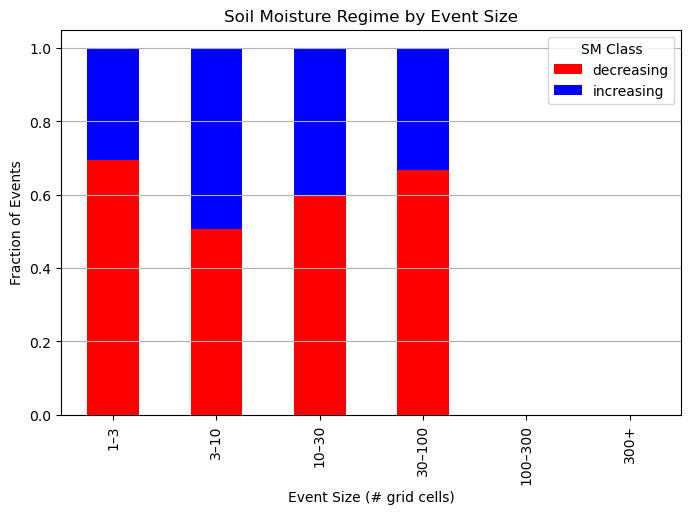

In [33]:
plot_df["size_bin"] = pd.cut(
    plot_df["event_size"],
    bins=[1, 3, 10, 30, 100, 300, 1000],
    labels=["1–3", "3–10", "10–30", "30–100", "100–300", "300+"])
size_sm_counts = (plot_df.groupby(["size_bin", "dominant_class"]).size().unstack(fill_value=0))
size_sm_frac = size_sm_counts.div(size_sm_counts.sum(axis=1), axis=0)

size_sm_frac.plot( kind="bar", stacked=True, figsize=(8,5), color=["red", "blue"])
plt.xlabel("Event Size (# grid cells)")
plt.ylabel("Fraction of Events")
plt.title("Soil Moisture Regime by Event Size")

plt.legend(title="SM Class")
plt.grid(axis="y")
plt.show()

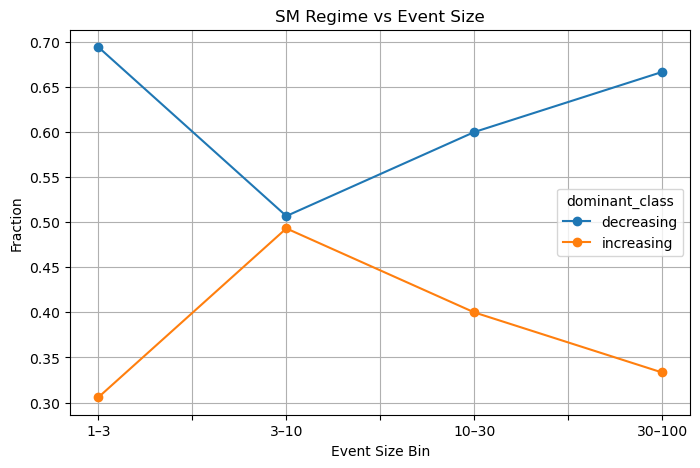

In [34]:
size_sm_frac.plot(marker="o",figsize=(8,5))
plt.xlabel("Event Size Bin")
plt.ylabel("Fraction")
plt.title("SM Regime vs Event Size")

plt.grid(True)
plt.show()